# 07 · Machine learning (3/3): finding groups of similar routes - **clustering** and **PCA**

So far we always had a target to predict (supervised learning). Here there is **no target**: we ask the computer to find **groups of routes that behave alike**.
That is **unsupervised learning**.

- **K-Means clustering** - split routes into `K` groups so that routes in a group look alike.
- **PCA (Principal Component Analysis)** - squeeze many columns into 2 so we can *draw* the routes and see the groups.

**Why it is useful for the project:** an operator would treat a *"morning commuter route"* differently from an *"all-day steady route"* - different buses, different timetable.

In [1]:
# --- Setup: run this cell first ---------------------------------------------------------------
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # lets the notebook find config.py and the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import db

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 140)

print("Data mode:", config.MODE.upper(), "| database:", config.DB_NAME if config.USE_MYSQL else "SQLite file")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

Data mode: REAL | database: SQLite file


## 1. Describe every route by its daily rhythm
For each route (weekdays) we take its crowd index in each time band, then:
- the **shape**: what share of its daily crowding falls in the morning peak, midday, evening peak ... (when is it busy?)
- the **level**: how crowded it is overall (log scale)

Only routes with at least 500 tickets are used, so the profiles are not noise.

In [2]:
engine = db.get_engine()
rl = db.read_table("crowd_route_level", engine)
attrs = db.read_table("route_attrs", engine)
BANDS = ["early", "am_peak", "midday", "pm_peak", "evening"]

prof = rl[(rl.daytype == "weekday") & rl.band.isin(BANDS)].pivot(index="route_n", columns="band", values="route_idx")[BANDS].fillna(0)
prof = prof.join(attrs.set_index("route_n")[["route", "is_ac", "n_tickets"]])
prof = prof[prof.n_tickets >= 500].copy()
level = prof[BANDS].mean(axis=1)
shape = prof[BANDS].div(prof[BANDS].sum(axis=1), axis=0)             # shares that add up to 1
F = shape.add_prefix("share_").assign(log_level=np.log1p(level))
print(f"{len(F)} routes clustered")
F.head()

796 routes clustered


,share_early,share_am_peak,share_midday,share_pm_peak,share_evening,log_level
route_n,,,,,,
102DOWN,0.051262,0.711889,0.191169,0.045680,0.000000,0.238433
102UP,0.000000,0.082942,0.073060,0.367818,0.476180,0.262825
103DOWN,0.173885,0.600278,0.093792,0.122636,0.009409,0.216352
103UP,0.001394,0.090903,0.114534,0.331064,0.462106,0.163035
106DOWN,0.240963,0.439130,0.173625,0.125611,0.020672,0.268611


## 2. How many groups? (choosing K)
K-Means needs us to choose K. Two helpers:
- **Elbow:** total distance of routes to their group centre (*inertia*) always falls as K grows - look for the bend.
- **Silhouette score:** how well each route fits its own group compared to the next-closest one (1 = perfect, 0 = on the border).

We **standardise** first (`StandardScaler`) so no column dominates just because its numbers are bigger.

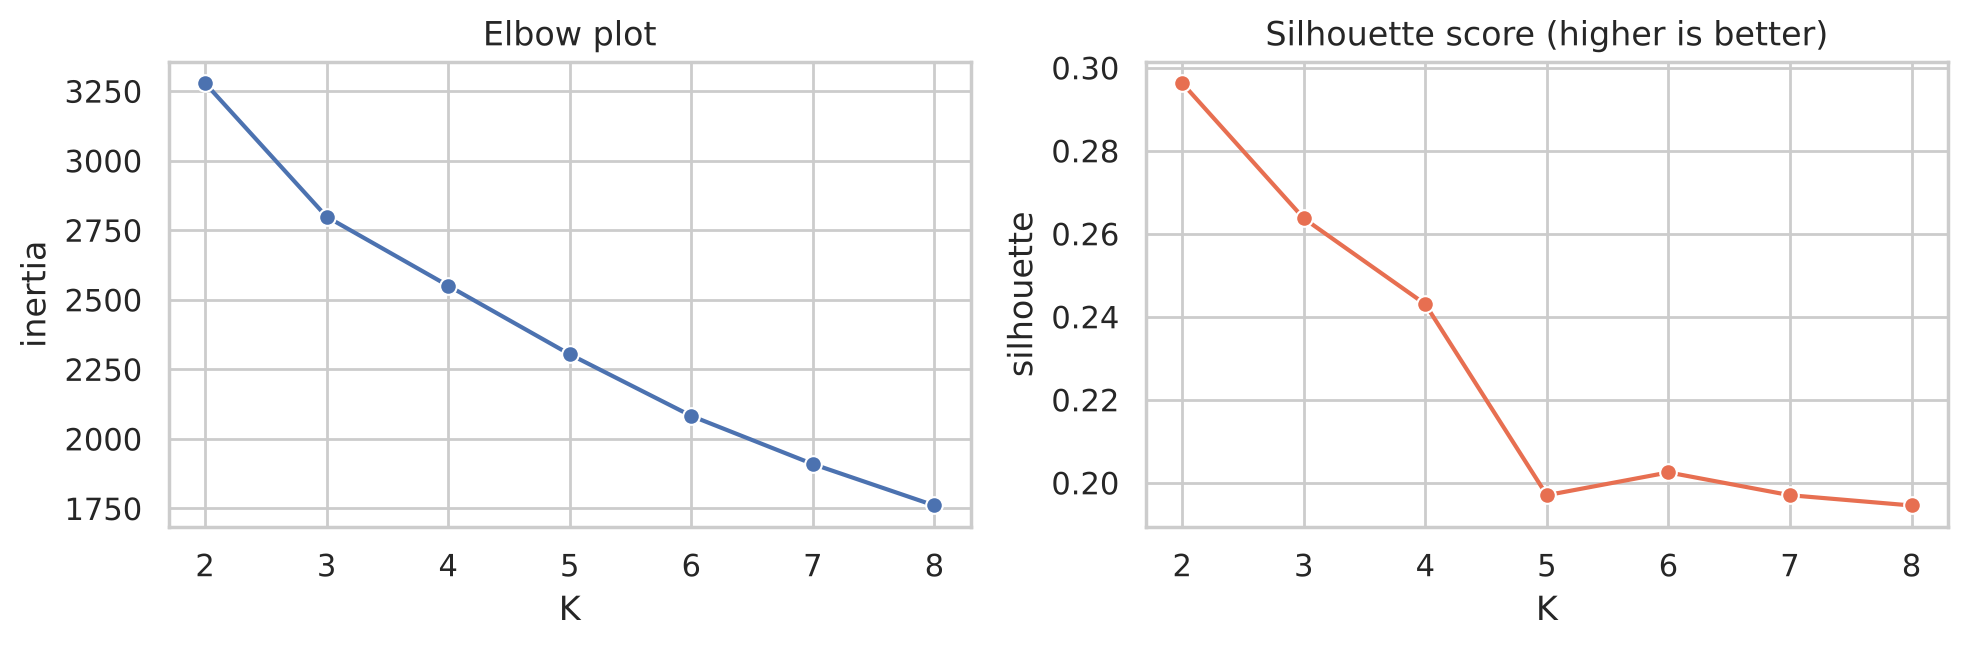

,K,inertia,silhouette
0,2,3278.479,0.296
1,3,2798.260,0.264
2,4,2550.281,0.243
3,5,2303.731,0.197
4,6,2082.343,0.202
5,7,1909.321,0.197
6,8,1760.365,0.195


In [3]:
Z = StandardScaler().fit_transform(F)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=config.RANDOM_STATE).fit(Z)
    rows.append((k, km.inertia_, silhouette_score(Z, km.labels_)))
sel = pd.DataFrame(rows, columns=["K", "inertia", "silhouette"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
sns.lineplot(data=sel, x="K", y="inertia", marker="o", ax=ax[0]); ax[0].set_title("Elbow plot")
sns.lineplot(data=sel, x="K", y="silhouette", marker="o", ax=ax[1], color="#e76f51"); ax[1].set_title("Silhouette score (higher is better)")
plt.tight_layout(); plt.show()
sel.round(3)

In [4]:
K = 4        # a readable number of groups; check the table above - you can change it and re-run
km = KMeans(n_clusters=K, n_init=10, random_state=config.RANDOM_STATE).fit(Z)
F["cluster"] = km.labels_
print("Routes per cluster:", F.cluster.value_counts().sort_index().to_dict())

Routes per cluster: {0: 125, 1: 293, 2: 90, 3: 288}


## 3. Draw the routes with PCA
We have 6 numbers per route - we cannot plot 6 dimensions. PCA finds the **two directions that keep the most information** and projects every route onto them.

Information kept by the 2 axes: 63% (PC1 43%, PC2 20%)


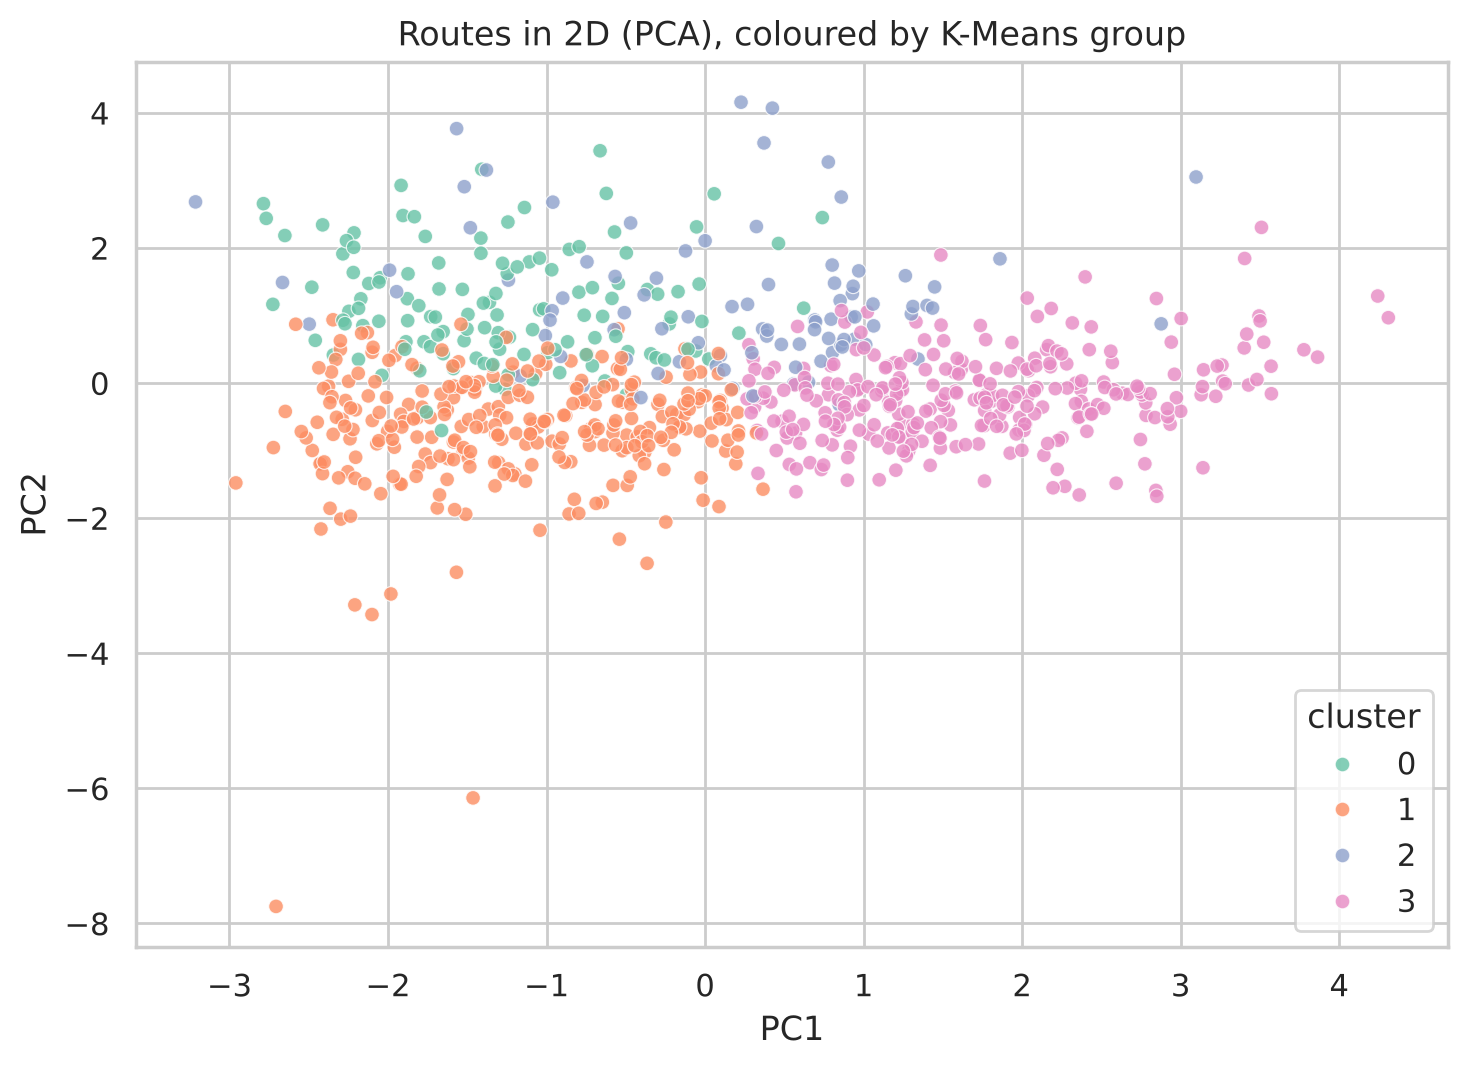

,PC1,PC2
share_early,-0.32,0.49
share_am_peak,-0.53,-0.07
share_midday,-0.26,-0.57
share_pm_peak,0.53,0.01
share_evening,0.51,0.05
log_level,-0.09,0.65


In [5]:
pca = PCA(n_components=2, random_state=config.RANDOM_STATE).fit(Z)
P = pca.transform(Z)
print("Information kept by the 2 axes: %.0f%% (PC1 %.0f%%, PC2 %.0f%%)" % (pca.explained_variance_ratio_.sum() * 100, *(pca.explained_variance_ratio_ * 100)))
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=F.cluster, palette="Set2", s=28, alpha=0.8)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Routes in 2D (PCA), coloured by K-Means group"); plt.tight_layout()
plt.savefig(config.FIG / "07_pca_clusters.png", dpi=130); plt.show()
load = pd.DataFrame(pca.components_.T, index=F.columns[:-1], columns=["PC1", "PC2"]).round(2); load

The table shows which original columns each axis is made of (its **loadings**) - this is how you *name* the axes.

## 4. What does each group look like?

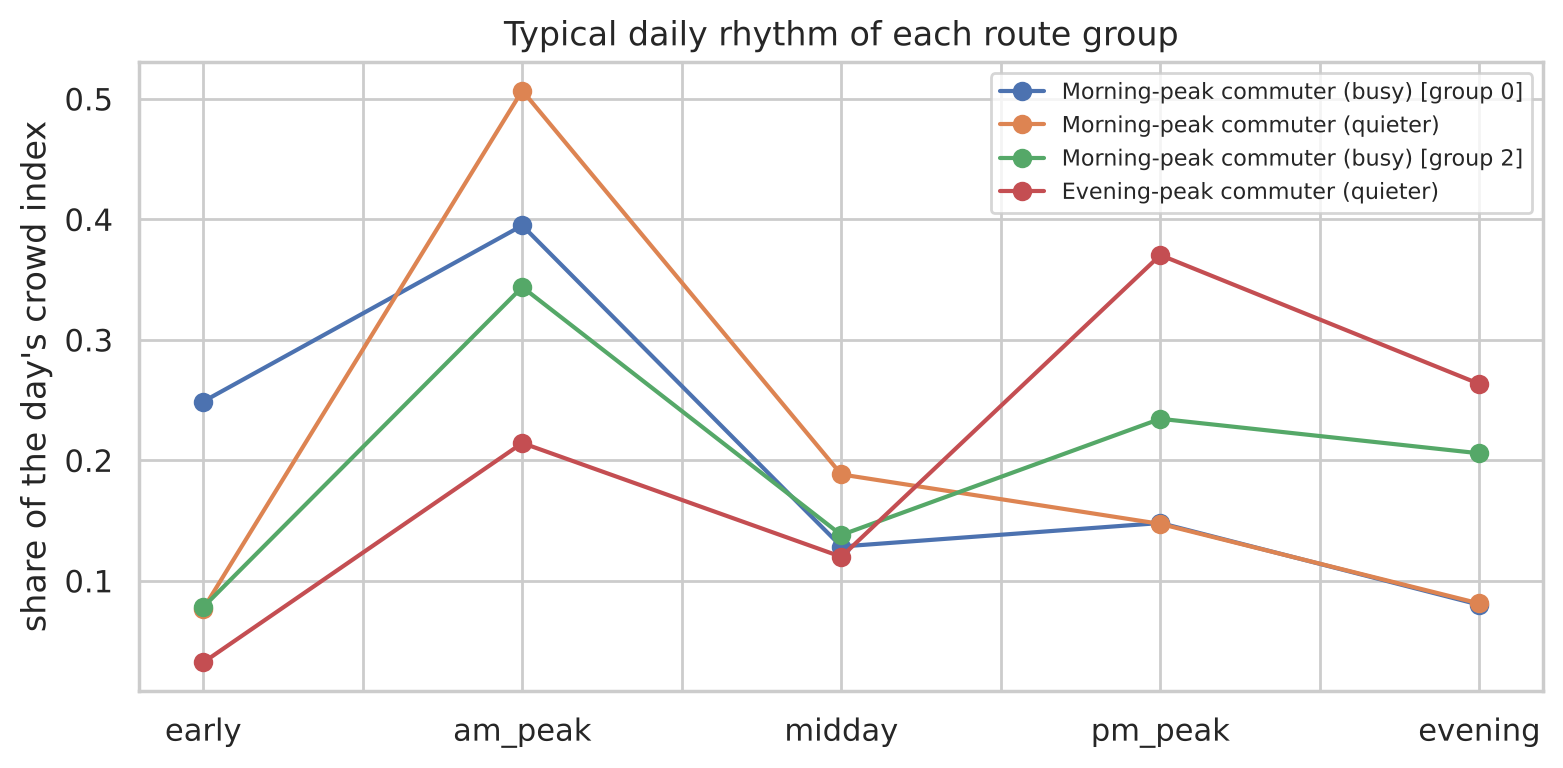

,routes,avg_log_level
label,,
Evening-peak commuter (quieter),288,0.30
Morning-peak commuter (busy) [group 0],125,0.44
Morning-peak commuter (busy) [group 2],90,0.75
Morning-peak commuter (quieter),293,0.31


In [6]:
mean_shape = F.groupby("cluster")[[c for c in F.columns if c.startswith("share_")]].mean()
mean_shape.columns = BANDS
lvl = F.groupby("cluster").log_level.mean(); overall = F.log_level.median()

def name_cluster(row, lv):
    peak = row.idxmax()
    base = {"am_peak": "Morning-peak commuter", "pm_peak": "Evening-peak commuter", "midday": "Midday / all-day", "evening": "Evening-heavy", "early": "Early-morning"}[peak]
    if row["am_peak"] > 0.28 and row["pm_peak"] > 0.28: base = "Two-peak commuter"
    if row.max() < 0.30: base = "Steady all-day"
    return base + (" (busy)" if lv > overall else " (quieter)")
labels = {c: name_cluster(mean_shape.loc[c], lvl[c]) for c in mean_shape.index}
dup = pd.Series(labels).value_counts(); dup = set(dup[dup > 1].index)
labels = {c: (l + f" [group {c}]" if l in dup else l) for c, l in labels.items()}        # keep every group name unique
F["label"] = F.cluster.map(labels)

plot = mean_shape.rename(index=labels).T
plot.plot(marker="o", figsize=(8, 4)); plt.ylabel("share of the day's crowd index"); plt.title("Typical daily rhythm of each route group"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(config.FIG / "07_cluster_profiles.png", dpi=130); plt.show()
summary = F.groupby("label").agg(routes=("cluster", "size")).join(F.groupby("label").log_level.mean().rename("avg_log_level")).round(2)
summary

In [7]:
ex = F.join(prof[["route", "n_tickets"]]).sort_values("n_tickets", ascending=False)
ex.groupby("label").head(4).sort_values(["label", "n_tickets"], ascending=[True, False])[["label", "route", "n_tickets"]].reset_index(drop=True)

,label,route,n_tickets
0,Evening-peak commuter (quieter),578UP,12730.0
1,Evening-peak commuter (quieter),448UP,7833.0
2,Evening-peak commuter (quieter),543ADOWN,7718.0
3,Evening-peak commuter (quieter),463DOWN,7552.0
4,Morning-peak commuter (busy) [group 0],511AUP,17506.0
5,Morning-peak commuter (busy) [group 0],729UP,16656.0
6,Morning-peak commuter (busy) [group 0],729DOWN,16502.0
7,Morning-peak commuter (busy) [group 0],623UP,15765.0
8,Morning-peak commuter (busy) [group 2],717AUP,25947.0
9,Morning-peak commuter (busy) [group 2],717ADOWN,25611.0


Each group has its own average **rhythm** (see the plot): morning-peak routes, evening-peak routes, and so on, each split by how busy it is overall. The names come from a simple rule
(`name_cluster`) applied to each group's average profile - always check them against the plot, and treat them as descriptions, not facts.

**Honest reading:** the silhouette score printed in section 2 is low (well below 0.5) and the PCA plot shows the groups **overlap** - routes lie on a smooth spectrum between "morning commuter" and "evening commuter" rather than in clean boxes.
Clustering is useful here for *describing* routes to an operator, not for assigning them to hard categories.

## 5. Save

In [8]:
out = F.reset_index()[["route_n", "cluster", "label"]].merge(prof.reset_index()[["route_n", "route", "n_tickets"]], on="route_n")
db.save_table(out, "route_clusters", engine, index_cols=["route_n"])
import json
(config.OUT / "07_clustering.json").write_text(json.dumps({"K": K, "routes": int(len(F)), "pca_variance_kept": round(float(pca.explained_variance_ratio_.sum()), 3),
                                                           "silhouette": round(float(silhouette_score(Z, km.labels_)), 3), "clusters": summary.reset_index().to_dict("records")}, indent=2, default=float))
print("saved: database table route_clusters")

saved: database table route_clusters


## Summary
| Lesson | Where |
|---|---|
| **Unsupervised learning** needs no target | whole notebook |
| **K-Means**: choose K with the elbow and silhouette | Section 2 |
| **Standardise** before distance-based methods | Section 2 |
| **PCA** reduces many columns to a few; loadings tell you what the axes mean | Section 3 |

**This completes the ML part.** The app (`app/streamlit_app.py`) uses the saved tables and models.